=== (a) TABEL AUC PER BULAN (2024) ===
periode   n  gagal_bayar    auc
2024-01 900           82 0.7881
2024-02 900           71 0.7183
2024-03 900           70 0.7440
2024-04 900           71 0.7744
2024-05 900           66 0.8122
2024-06 900           95 0.7681
2024-07 900           99 0.7798
2024-08 900          101 0.7560
2024-09 900          112 0.7726
2024-10 900           88 0.7902
2024-11 900           94 0.7525
2024-12 900          110 0.7923


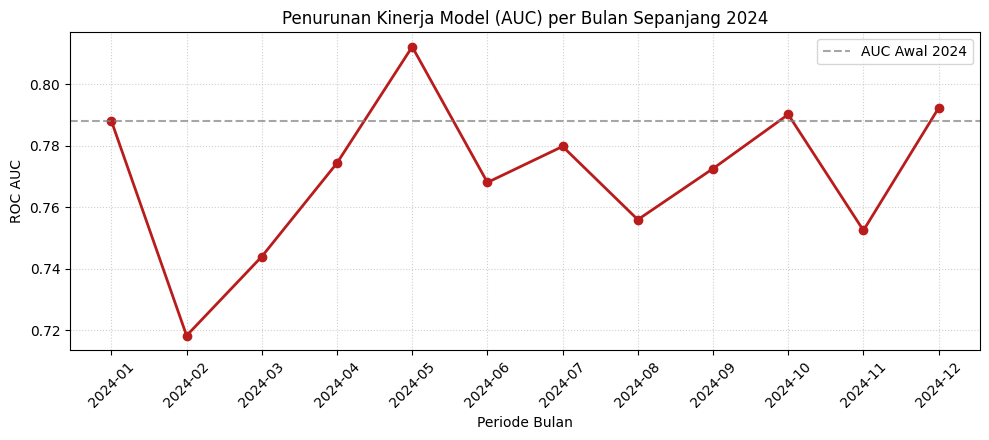


=== (b) PERGESERAN KOMPOSISI SEGMEN ===
                  awal (<=2022-06)  akhir (>=2024-07)  selisih
segmen                                                        
pegawai_tetap                0.414              0.311   -0.103
wiraswasta                   0.251              0.232   -0.018
pedagang_musiman             0.141              0.179    0.038
petani                       0.129              0.167    0.038
nelayan                      0.066              0.111    0.045

=== (c) KINERJA PER SEGMEN (> 2024-06) ===
          segmen    n  tingkat_gagal_bayar   auc
          petani  904               0.1361 0.705
pedagang_musiman  965               0.1368 0.766
      wiraswasta 1254               0.1069 0.773
   pegawai_tetap 1680               0.0774 0.784
         nelayan  597               0.1424 0.794
[CHECKPOINT TERSIMPAN] 'prak02_selesai' -> artifacts\checkpoints\prak02_selesai
  - Hash Dataset : 8b8cccee35b7229a
  - Variabel     : ['auc_bulanan_2024', 'pergeseran_segmen', 'ki

WindowsPath('artifacts/checkpoints/prak02_selesai')

In [2]:
import os
import sys
from pathlib import Path

# Pastikan direktori kerja & sys.path mengarah ke akar proyek sebelum import src
if Path.cwd().name == "notebooks":
    os.chdir("..")
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score
from src.checkpoint import simpan_checkpoint

df = pd.read_csv("data/raw/kredit_sumatera.csv")

# Siapkan fitur sesuai skema asli dataset (buang status_restrukturisasi yang bocor)
df["rasio_angsuran"] = df["angsuran_bulanan"] / df["penghasilan_bulanan"]
num = [
    "usia", "tanggungan", "lama_usaha_tahun", "penghasilan_bulanan",
    "ragam_penghasilan", "plafon_diajukan", "tenor_bulan", "bunga_tahunan",
    "rasio_angsuran", "rata_saldo_90h", "jumlah_tunggakan_12b"
]
X_all = df[num].join(pd.get_dummies(df[["segmen", "wilayah", "kanal"]]))
y_all = df["gagal_bayar"]

# Latih model pada 2022-2023 lalu bekukan
mask_latih = df["periode"] <= "2023-12"
mask_uji = df["periode"] >= "2024-01"

model = HistGradientBoostingClassifier(
    max_depth=6, learning_rate=0.06, max_iter=250, random_state=42
)
model.fit(X_all[mask_latih], y_all[mask_latih])

# --- (a) Tabel & Grafik Penurunan AUC per Bulan pada 2024 ---
hasil_bulanan = []
for bln, grup in df[mask_uji].groupby("periode"):
    idx = grup.index
    if y_all.loc[idx].nunique() < 2:
        continue
    prob = model.predict_proba(X_all.loc[idx])[:, 1]
    auc = roc_auc_score(y_all.loc[idx], prob)
    hasil_bulanan.append({
        "periode": bln,
        "n": len(idx),
        "gagal_bayar": int(y_all.loc[idx].sum()),
        "auc": round(auc, 4)
    })

df_bulanan = pd.DataFrame(hasil_bulanan)
print("=== (a) TABEL AUC PER BULAN (2024) ===")
print(df_bulanan.to_string(index=False))

plt.figure(figsize=(10, 4.5))
plt.plot(df_bulanan["periode"], df_bulanan["auc"], marker="o", linewidth=2, color="#b91c1c")
plt.axhline(df_bulanan["auc"].iloc[0], linestyle="--", color="gray", alpha=0.7, label="AUC Awal 2024")
plt.title("Penurunan Kinerja Model (AUC) per Bulan Sepanjang 2024")
plt.xlabel("Periode Bulan")
plt.ylabel("ROC AUC")
plt.xticks(rotation=45)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# --- (b) Pergeseran Komposisi Populasi (Awal vs Akhir) ---
awal = df[df["periode"] <= "2022-06"]["segmen"].value_counts(normalize=True)
akhir = df[df["periode"] >= "2024-07"]["segmen"].value_counts(normalize=True)
df_geser = pd.DataFrame({
    "awal (<=2022-06)": awal,
    "akhir (>=2024-07)": akhir
})
df_geser["selisih"] = df_geser["akhir (>=2024-07)"] - df_geser["awal (<=2022-06)"]
print("\n=== (b) PERGESERAN KOMPOSISI SEGMEN ===")
print(df_geser.round(3))

# --- (c) Analisis Kinerja per Segmen (> 2024-06) ---
mask_akhir = df["periode"] > "2024-06"
hasil_segmen = []
for seg, grup in df[mask_akhir].groupby("segmen"):
    idx = grup.index
    prob = model.predict_proba(X_all.loc[idx])[:, 1]
    auc_seg = roc_auc_score(y_all.loc[idx], prob)
    hasil_segmen.append({
        "segmen": seg,
        "n": len(idx),
        "tingkat_gagal_bayar": round(y_all.loc[idx].mean(), 4),
        "auc": round(auc_seg, 3)
    })

df_segmen = pd.DataFrame(hasil_segmen).sort_values("auc")
print("\n=== (c) KINERJA PER SEGMEN (> 2024-06) ===")
print(df_segmen.to_string(index=False))

# Simpan checkpoint hasil Praktikum 2
simpan_checkpoint(
    "prak02_selesai",
    variabel_dict={
        "auc_bulanan_2024": df_bulanan,
        "pergeseran_segmen": df_geser,
        "kinerja_segmen": df_segmen,
        "segmen_terlemah": df_segmen.iloc[0]["segmen"]
    },
    model=model
)